# Pandas Korrelation: Pearson, Spearman und die dritte Variable
### Unterrichtsmaterial | Julia Brutskaya

---
**Kontext:** Kurs-Umfrage der Datenwald-Akademie<br>
**Bibliotheken:** `pandas`, `numpy`, `matplotlib`

<img src="png%20Dateien/nils_eichhoernchen.png" alt="Nils" width="150"> <img src="png%20Dateien/etta_elster.png" alt="Etta" width="150"> <img src="png%20Dateien/mats_maulwurf.png" alt="Mats Maulwurf" width="150">

Du hast bisher r und ρ mit Stift und Taschenrechner bestimmt. Jetzt rechnet Pandas dieselben Zahlen nach, für alle 20 Befragten und für ganze Tabellen auf einmal.

| Figur | Rolle heute | In Pandas |
|---|---|---|
| **Nils** | rechnet mit Abweichungen: Pearson | `corr()` |
| **Etta** | denkt in Ranglisten: Spearman | `rank()`, `corr(method="spearman")` |
| **Der Ausreißer** | Person 110, zieht an r | mit und ohne vergleichen |
| **Mats Maulwurf** (neu) | die dritte Variable, die man nicht sieht | Daten, die im Datensatz fehlen |

Herr Bauchgefühl ist auch wieder da. Heute verwechselt er Zusammenhang und Ursache.

| Block | Inhalt |
|---|---|
| A | Vom Mittelwert-Kreuz zu Pearson r |
| B | r lesen und seine Grenzen |
| C | Spearman und Ränge |
| D | Korrelation ist nicht Kausalität |
| E | Die Korrelationsmatrix |
| F | Weitere Übungen |

---
# Block A – Vom Mittelwert-Kreuz zu Pearson r

## 1 – Die Kurs-Umfrage laden

Die Umfrage hat seit gestern zwei Spalten mehr: `lernstunden` (pro Woche zu Hause) und `punkte` (in der Zwischenprüfung).

In [1]:
# pip install scipy

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Kurs-Umfrage der Datenwald-Akademie: eine Zeile pro befragter Person
zeilen = [
    # teilnehmer_id, kurszeit, getraenk, tshirt, haustiere, anfahrt_min, lernstunden, punkte
    (101, "Vormittag", "Kaffee", "M", 0, 25, 3, 50), (102, "Abend", "Tee", "S", 1, 35, 4, 58),
    (103, "Vormittag", "Mate", "L", 0, 18, 4, 63), (104, "Vormittag", "Kaffee", "L", 2, 42, 9, 81),
    (105, "Abend", "Wasser", "M", 0, 30, 8, 84), (106, "Vormittag", "Tee", "M", 1, 28, 5, 60),
    (107, "Abend", "Kaffee", "XL", 0, 55, 9, 86), (108, "Vormittag", "Kaffee", "S", 3, 12, 7, 79),
    (109, "Vormittag", "Mate", "M", 1, 38, 3, 57), (110, "Abend", "Tee", "M", 0, 115, 12, 66),
    (111, "Vormittag", "Kaffee", "L", 0, 32, 10, 88), (112, "Abend", "Mate", "L", 2, 45, 1, 47),
    (113, "Vormittag", "Wasser", "S", 1, 22, 6, 72), (114, "Vormittag", "Kaffee", "M", 0, 35, 5, 62),
    (115, "Abend", "Tee", "L", 1, 48, 11, 94), (116, "Vormittag", "Tee", "M", 0, 30, 8, 76),
    (117, "Abend", "Kaffee", "M", 3, 65, 2, 52), (118, "Vormittag", "Mate", "XL", 1, 40, 6, 69),
    (119, "Abend", "Wasser", "S", 0, 52, 7, 70), (120, "Vormittag", "Kaffee", "L", 2, 25, 6, 61),
]
spalten = ["teilnehmer_id", "kurszeit", "getraenk", "tshirt", "haustiere",
           "anfahrt_min", "lernstunden", "punkte"]
umfrage = pd.DataFrame(zeilen, columns=spalten)

BLAU, ORANGE = "#2a78d6", "#eb6834"

umfrage.head()

,teilnehmer_id,kurszeit,getraenk,tshirt,haustiere,anfahrt_min,lernstunden,punkte
0,101,Vormittag,Kaffee,M,0,25,3,50
1,102,Abend,Tee,S,1,35,4,58
2,103,Vormittag,Mate,L,0,18,4,63
3,104,Vormittag,Kaffee,L,2,42,9,81
4,105,Abend,Wasser,M,0,30,8,84


## 2 – Das Mittelwert-Kreuz

<img src="png%20Dateien/herr_bauchgefuehl.png" alt="Herr Bauchgefühl" width="130">

> **Herr Bauchgefühl:** „Gestern hieß es, der Zusammenhang sei ‚stark'. Stark ist Geschmackssache. Ich sage: mittel."

Zuerst das Bild von heute Vormittag: Streudiagramm, dazu eine senkrechte Linie beim Mittelwert der Lernstunden und eine waagerechte beim Mittelwert der Punkte.

Mittelwert Lernstunden: 6.3
Mittelwert Punkte:      68.75


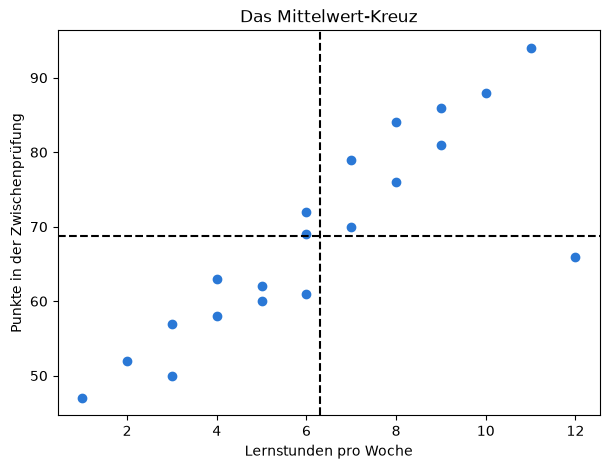

In [3]:
x = umfrage["lernstunden"]
y = umfrage["punkte"]
print("Mittelwert Lernstunden:", x.mean())
print("Mittelwert Punkte:     ", y.mean())

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, color=BLAU)
ax.axvline(x.mean(), color="black", linestyle="--")   # senkrechte Linie
ax.axhline(y.mean(), color="black", linestyle="--")   # waagerechte Linie
ax.set_xlabel("Lernstunden pro Woche")
ax.set_ylabel("Punkte in der Zwischenprüfung")
ax.set_title("Das Mittelwert-Kreuz")
plt.show()

<img src="png%20Dateien/nils_eichhoernchen.png" alt="Nils" width="110">

**Nils:** „Abweichungen vom Mittelwert kenne ich von der Varianz. Neu ist nur, dass ich zwei davon multipliziere."

Für jede Person: Abweichung bei den Stunden (`dx`), Abweichung bei den Punkten (`dy`) und das Produkt. Rechts oben und links unten ist das Produkt positiv.

In [4]:
abw = pd.DataFrame({
    "dx": x - x.mean(),
    "dy": y - y.mean(),
})
abw["produkt"] = abw["dx"] * abw["dy"]

print(abw.round(2).head())
print()
print("Punkte in den Plus-Feldern:", (abw["produkt"] > 0).sum(), "von", len(abw))
print("Summe der Produkte:        ", round(abw["produkt"].sum(), 2))

    dx     dy  produkt
0 -3.3 -18.75    61.88
1 -2.3 -10.75    24.72
2 -2.3  -5.75    13.22
3  2.7  12.25    33.08
4  1.7  15.25    25.93

Punkte in den Plus-Feldern: 17 von 20
Summe der Produkte:         647.5


17 von 20 Punkten liegen in den Plus-Feldern, die Summe der Produkte ist deutlich positiv. Der Zusammenhang ist also positiv.

## 3 – Die Kovarianz

Die Summe der Produkte geteilt durch n − 1 heißt **Kovarianz**. Pandas berechnet sie mit `cov()`.

In [5]:
kov_hand = abw["produkt"].sum() / (len(abw) - 1)

print("Kovarianz von Hand:", round(kov_hand, 2))
print("Kovarianz Pandas:  ", round(x.cov(y), 2))

Kovarianz von Hand: 34.08
Kovarianz Pandas:   34.08


Das Problem der Kovarianz: Sie hängt von den Einheiten ab. Rechnest du die Lernstunden in Minuten um, wird sie 60-mal so groß. Am Zusammenhang hat sich nichts geändert.

In [6]:
minuten = x * 60

print("Kovarianz mit Stunden:", round(x.cov(y), 1))
print("Kovarianz mit Minuten:", round(minuten.cov(y), 1))
print()
print("r mit Stunden:", round(x.corr(y), 2))
print("r mit Minuten:", round(minuten.corr(y), 2))

Kovarianz mit Stunden: 34.1
Kovarianz mit Minuten: 2044.7

r mit Stunden: 0.84
r mit Minuten: 0.84


Die Kovarianz springt von 34,1 auf 2044,7. Der Korrelationskoeffizient r bleibt bei 0,84. Genau dafür teilt man noch einmal.

## 4 – Pearson r Schritt für Schritt

Das Beispiel aus dem Skript: fünf Personen, x sind die Lernstunden, y die Punkte. Die Formel:

r = Σ (x − x̄) · (y − ȳ) / √( Σ (x − x̄)² · Σ (y − ȳ)² )

In [7]:
bsp = pd.DataFrame({"x": [2, 4, 6, 8, 10], "y": [55, 60, 70, 65, 75]})

# Spalten wie in der Handtabelle
bsp["x_abw"] = bsp["x"] - bsp["x"].mean()
bsp["y_abw"] = bsp["y"] - bsp["y"].mean()
bsp["produkt"] = bsp["x_abw"] * bsp["y_abw"]
bsp["x_abw_qu"] = bsp["x_abw"] ** 2
bsp["y_abw_qu"] = bsp["y_abw"] ** 2
print(bsp)
print()

summe_produkt = bsp["produkt"].sum()
summe_x_qu = bsp["x_abw_qu"].sum()
summe_y_qu = bsp["y_abw_qu"].sum()
print("Summen:", summe_produkt, summe_x_qu, summe_y_qu)

r_hand = summe_produkt / (summe_x_qu * summe_y_qu) ** 0.5
print("r von Hand:", r_hand)

    x   y  x_abw  y_abw  produkt  x_abw_qu  y_abw_qu
0   2  55   -4.0  -10.0     40.0      16.0     100.0
1   4  60   -2.0   -5.0     10.0       4.0      25.0
2   6  70    0.0    5.0      0.0       0.0      25.0
3   8  65    2.0    0.0      0.0       4.0       0.0
4  10  75    4.0   10.0     40.0      16.0     100.0

Summen: 90.0 40.0 250.0
r von Hand: 0.9


Die Summen 90, 40 und 250 und das Ergebnis 0,9 kennst du vom Vormittag. `** 0.5` ist die Wurzel.

In Pandas geht das in einer Zeile: `spalte_1.corr(spalte_2)`.

In [8]:
print("r mit corr():", round(bsp["x"].corr(bsp["y"]), 2))
print()
print("Kurs-Umfrage, alle 20:", round(umfrage["lernstunden"].corr(umfrage["punkte"]), 2))

r mit corr(): 0.9

Kurs-Umfrage, alle 20: 0.84


<img src="png%20Dateien/herr_bauchgefuehl_verdutzt.png" alt="Herr Bauchgefühl stutzt" width="130">

r = 0,84 ist nach der Faustregel ein **starker** Zusammenhang (ab 0,7). „Mittel" war also falsch.

### Übung 1

Untersuche `anfahrt_min` (x) und `punkte` (y).

- **a)** Zeichne das Streudiagramm mit Mittelwert-Kreuz.
- **b)** Wie viele Punkte liegen in den Plus-Feldern?
- **c)** Berechne r von Hand wie in Abschnitt 4 und prüfe mit `corr()`. Wie stark ist der Zusammenhang?

In [9]:
# a)


In [10]:
# b)


In [11]:
# c)


---
# Block B – r lesen und seine Grenzen

## 5 – Wie sieht welches r aus?

Mit NumPy erzeugen wir Punktwolken mit einem vorgegebenen r. `np.random.default_rng(6)` startet den Zufallsgenerator immer gleich, deshalb sieht bei allen dieselbe Wolke gleich aus.

Du musst die Erzeugung nicht im Detail verstehen. Wichtig ist das Bild.

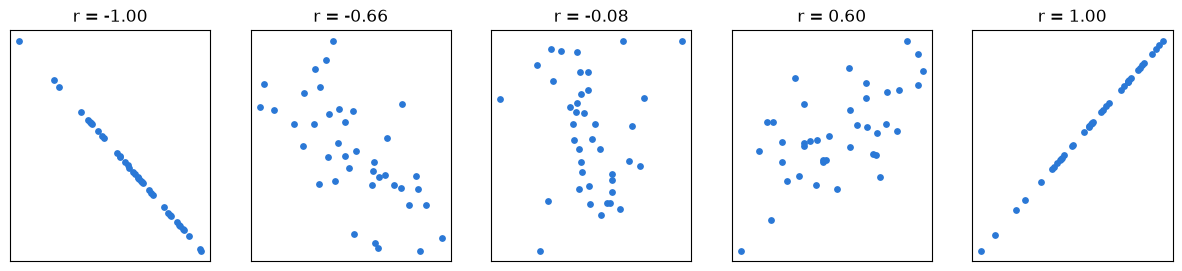

In [12]:
zufall = np.random.default_rng(6)
ziel_werte = [-1, -0.7, 0, 0.7, 1]

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, ziel in zip(axes, ziel_werte):
    a = zufall.normal(size=40)
    b = ziel * a + (1 - ziel ** 2) ** 0.5 * zufall.normal(size=40)
    r = pd.Series(a).corr(pd.Series(b))
    ax.scatter(a, b, color=BLAU, s=15)
    ax.set_title(f"r = {r:.2f}")
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

- **Vorzeichen** = Richtung: plus heißt „je mehr, desto mehr", minus „je mehr, desto weniger".
- **Betrag** = Stärke: unter 0,3 schwach, 0,3 bis unter 0,7 mittel, ab 0,7 stark.
- r hat **keine Einheit** und ist **keine Steigung**.

## 6 – Der Ausreißer zieht an r

<img src="png%20Dateien/der_ausreisser.png" alt="Der Ausreißer" width="130">

**Der Ausreißer:** „Ich sitze rechts unten im Minus-Feld: viele Stunden, wenig Punkte. Ich ziehe die Summe nach unten."

Person 110 lernt 12 Stunden und hat nur 66 Punkte. Wir rechnen r mit und ohne sie.

alle 20 Personen: 0.84
ohne Person 110:  0.96


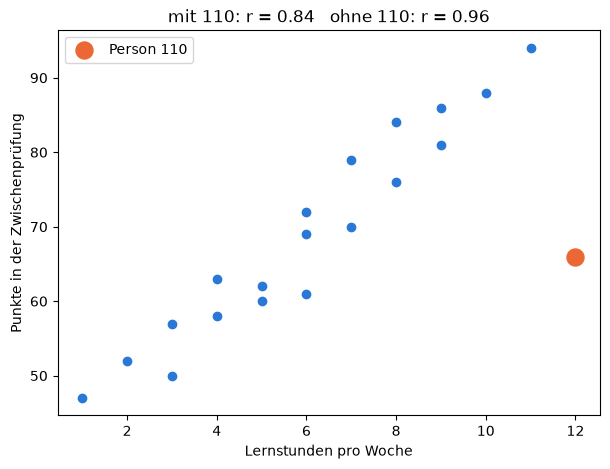

In [13]:
ohne_110 = umfrage[umfrage["teilnehmer_id"] != 110]

r_alle = umfrage["lernstunden"].corr(umfrage["punkte"])
r_ohne = ohne_110["lernstunden"].corr(ohne_110["punkte"])
print("alle 20 Personen:", round(r_alle, 2))
print("ohne Person 110: ", round(r_ohne, 2))

p110 = umfrage[umfrage["teilnehmer_id"] == 110]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(umfrage["lernstunden"], umfrage["punkte"], color=BLAU)
ax.scatter(p110["lernstunden"], p110["punkte"], color=ORANGE, s=150, label="Person 110")
ax.set_xlabel("Lernstunden pro Woche")
ax.set_ylabel("Punkte in der Zwischenprüfung")
ax.set_title(f"mit 110: r = {r_alle:.2f}   ohne 110: r = {r_ohne:.2f}")
ax.legend()
plt.show()

Ein einziger Punkt, und r fällt von 0,96 auf 0,84. Trotzdem wird Person 110 nicht einfach gelöscht. Wie an Tag 3 gilt: erst prüfen, ob es ein Fehler ist, und im Zweifel beide Werte angeben.

## 7 – r misst nur gerade Zusammenhänge

Zwei Beispiele aus dem Skript: Nervosität und Leistung (ein Bogen) und Übungswochen und Tippgeschwindigkeit (eine Kurve, die abflacht).

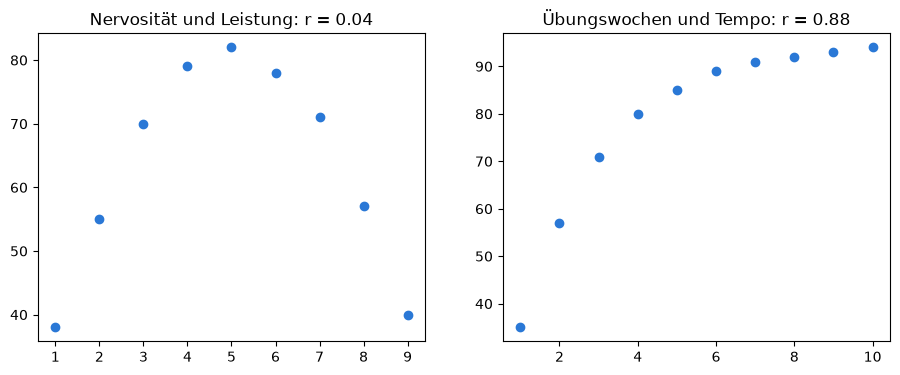

In [14]:
bogen = pd.DataFrame({"nervositaet": range(1, 10),
                      "punkte": [38, 55, 70, 79, 82, 78, 71, 57, 40]})
tempo = pd.DataFrame({"wochen": range(1, 11),
                      "wpm": [35, 57, 71, 80, 85, 89, 91, 92, 93, 94]})

r_bogen = bogen["nervositaet"].corr(bogen["punkte"])
r_tempo = tempo["wochen"].corr(tempo["wpm"])

fig, (links, rechts) = plt.subplots(1, 2, figsize=(11, 4))
links.scatter(bogen["nervositaet"], bogen["punkte"], color=BLAU)
links.set_title(f"Nervosität und Leistung: r = {r_bogen:.2f}")
rechts.scatter(tempo["wochen"], tempo["wpm"], color=BLAU)
rechts.set_title(f"Übungswochen und Tempo: r = {r_tempo:.2f}")
plt.show()

<img src="png%20Dateien/herr_bauchgefuehl_verdutzt.png" alt="Herr Bauchgefühl stutzt" width="130">

> **Herr Bauchgefühl:** „r = 0,04 bei so einem schönen Bogen. Ich hole das Streudiagramm wieder aus dem Papierkorb."

Links ist r fast 0, obwohl ein klares Muster da ist. Rechts ist der Zusammenhang perfekt (immer mehr Tempo), r ist trotzdem nur 0,88. Dafür kommt gleich Spearman.

> **Merke:** Erst das Streudiagramm anschauen, dann r berechnen.

### Übung 2

Untersuche `anfahrt_min` (x) und `lernstunden` (y).

- **a)** Berechne r für alle 20 Personen.
- **b)** Zeichne das Streudiagramm und markiere Person 110.
- **c)** Berechne r ohne Person 110. Was fällt dir auf?

In [15]:
# a)


In [16]:
# b)


In [17]:
# c)


---
# Block C – Spearman und Ränge

## 8 – Ränge mit `rank()`

<img src="png%20Dateien/etta_elster.png" alt="Etta" width="120">

**Etta:** „Platz 1, Platz 2, Platz 3: Ranglisten sind ordinal. Abstände gibt es da nicht, nur eine Reihenfolge. Genau dafür ist Spearman da."

`rank()` ersetzt jeden Wert durch seinen Rang. Der kleinste Wert bekommt Rang 1. Bei gleichen Werten gibt es den Durchschnitt der Ränge.

In [18]:
anfahrt_bsp = pd.Series([12, 15, 15, 20, 31])
print(pd.DataFrame({"wert": anfahrt_bsp, "rang": anfahrt_bsp.rank()}))

   wert  rang
0    12   1.0
1    15   2.5
2    15   2.5
3    20   4.0
4    31   5.0


Die beiden 15er teilen sich die Plätze 2 und 3, beide bekommen Rang 2,5.

## 9 – Spearman mit `corr(method="spearman")`

Das Hackathon-Beispiel: Etta und Nils haben sechs Teams auf die Plätze 1 bis 6 gesetzt.

In [19]:
jury = pd.DataFrame({"etta": [1, 2, 3, 4, 5, 6],
                     "nils": [2, 1, 4, 3, 6, 5]}, index=list("ABCDEF"))

# Kurzformel wie am Vormittag (nur ohne gleiche Werte)
d = jury["etta"] - jury["nils"]
n = len(jury)
rho_hand = 1 - 6 * (d ** 2).sum() / (n * (n ** 2 - 1))

print("rho von Hand:", round(rho_hand, 2))
print("rho Pandas:  ", round(jury["etta"].corr(jury["nils"], method="spearman"), 2))

rho von Hand: 0.83
rho Pandas:   0.83


Programme rechnen Spearman anders als die Kurzformel: Sie bilden die Ränge und berechnen darauf das ganz normale Pearson-r. Das klappt auch bei gleichen Werten.

In [20]:
lern = umfrage["lernstunden"]
punkte = umfrage["punkte"]

rho = lern.corr(punkte, method="spearman")
pearson_auf_raengen = lern.rank().corr(punkte.rank())

print("Spearman:            ", round(rho, 2))
print("Pearson auf Rängen:  ", round(pearson_auf_raengen, 2))

Spearman:             0.88
Pearson auf Rängen:   0.88


## 10 – Pearson und Spearman im Vergleich

Spearman ist robuster: Ein Rang kann höchstens n sein, egal wie extrem der Wert ist. Und Spearman misst jeden **monotonen** Zusammenhang, nicht nur gerade.

In [21]:
vergleich = pd.DataFrame({
    "Pearson": [
        umfrage["lernstunden"].corr(umfrage["punkte"]),
        ohne_110["lernstunden"].corr(ohne_110["punkte"]),
        tempo["wochen"].corr(tempo["wpm"]),
    ],
    "Spearman": [
        umfrage["lernstunden"].corr(umfrage["punkte"], method="spearman"),
        ohne_110["lernstunden"].corr(ohne_110["punkte"], method="spearman"),
        tempo["wochen"].corr(tempo["wpm"], method="spearman"),
    ],
}, index=["Lernen/Punkte, alle 20", "Lernen/Punkte, ohne 110", "Übungswochen/Tempo"])

vergleich.round(2)

,Pearson,Spearman
"Lernen/Punkte, alle 20",0.84,0.88
"Lernen/Punkte, ohne 110",0.96,0.96
Übungswochen/Tempo,0.88,1.00


- Person 110 bewegt Pearson von 0,84 auf 0,96, Spearman nur von 0,88 auf 0,96.
- Beim Tempo ist der Zusammenhang perfekt monoton: Spearman = 1,00, Pearson nur 0,88.

## 11 – Ordinale Merkmale: die T-Shirt-Größe

`corr()` braucht Zahlen. T-Shirt-Größen sind Text. Als geordnete Kategorie kennt Pandas die Reihenfolge, `.codes` liefert die Nummern 0, 1, 2, 3.

In [22]:
groesse = pd.Categorical(umfrage["tshirt"], categories=["S", "M", "L", "XL"], ordered=True)
umfrage["tshirt_nr"] = groesse.codes

print(umfrage[["tshirt", "tshirt_nr"]].head())
print()
print("Spearman T-Shirt / Lernstunden:",
      round(umfrage["tshirt_nr"].corr(umfrage["lernstunden"], method="spearman"), 2))

  tshirt  tshirt_nr
0      M          1
1      S          0
2      L          2
3      L          2
4      M          1

Spearman T-Shirt / Lernstunden: 0.19


> **Achtung:** Ohne Kategorie würde Pandas alphabetisch sortieren: L, M, S, XL. Dann wäre die Reihenfolge falsch.

Ergebnis: ρ = 0,19, schwach. Die T-Shirt-Größe hat mit den Lernstunden kaum etwas zu tun.

### Übung 3

- **a)** Bilde die Ränge der Spalte `lernstunden`. Welchen Rang bekommen die drei Personen mit 6 Stunden? Warum?
- **b)** Berechne Pearson und Spearman für `anfahrt_min` und `punkte`.
- **c)** Berechne Spearman für `tshirt_nr` und `punkte`.

In [23]:
# a)


In [24]:
# b)


In [25]:
# c)


---
# Block D – Korrelation ist nicht Kausalität

## 12 – Zwei Dinge, die zusammen wachsen

<img src="png%20Dateien/herr_bauchgefuehl.png" alt="Herr Bauchgefühl" width="130">

> **Herr Bauchgefühl:** „Lernstunden und Punkte: r = 0,84. Damit ist bewiesen, dass Lernen Punkte bringt. Und gestern habe ich gezeigt, dass Kaffee Anmeldungen bringt."

Ein Beispiel mit **frei erfundenen** Zahlen: Teilnehmende der Akademie und der Preis für eine Kugel Eis im Café nebenan.

In [26]:
# Frei erfundene Werte, nur zur Demonstration
trend = pd.DataFrame({
    "jahr": range(2019, 2027),
    "teilnehmende": [52, 55, 58, 61, 63, 66, 67, 68],
    "eispreis": [1.20, 1.30, 1.40, 1.50, 1.70, 1.80, 1.90, 2.00],
})

print("r Teilnehmende / Eispreis:", round(trend["teilnehmende"].corr(trend["eispreis"]), 2))
print("r Jahr / Teilnehmende:    ", round(trend["jahr"].corr(trend["teilnehmende"]), 2))
print("r Jahr / Eispreis:        ", round(trend["jahr"].corr(trend["eispreis"]), 2))

r Teilnehmende / Eispreis: 0.98
r Jahr / Teilnehmende:     0.99
r Jahr / Eispreis:         1.0


<img src="png%20Dateien/mats_maulwurf_huegel.png" alt="Mats Maulwurf" width="150">

**Mats Maulwurf:** „Ihr seht zwei Hügel, die zusammen wachsen. Mich seht ihr nicht. Hier bin ich die Zeit."

Treibt die Akademie den Eispreis hoch? Nein. Beide wachsen nur mit den Jahren. Die Jahre sind die dritte Variable.

## 13 – Vier Fragen an jede Korrelation

1. Gibt es eine **dritte Variable**, die beide beeinflusst?
2. Könnte die **Richtung umgekehrt** sein?
3. Wachsen beide nur mit der **Zeit**, oder ist die **Stichprobe sehr klein**?
4. Gab es ein **Experiment mit Zufallsgruppen**?

Zu Frage 3 ein Versuch: Wir ziehen zwei Spalten mit reinen Zufallszahlen, die nichts miteinander zu tun haben, und berechnen r. Das wiederholen wir 1000-mal.

In [27]:
zufall = np.random.default_rng(1)

for n in [5, 50]:
    starke_r = 0
    for _ in range(1000):
        a = pd.Series(zufall.normal(size=n))
        b = pd.Series(zufall.normal(size=n))
        if abs(a.corr(b)) >= 0.7:
            starke_r += 1
    print(f"n = {n:2}: {starke_r} von 1000 Versuchen mit |r| >= 0,7")

n =  5: 179 von 1000 Versuchen mit |r| >= 0,7
n = 50: 0 von 1000 Versuchen mit |r| >= 0,7


Bei nur 5 Werten zeigt fast jeder fünfte Versuch einen „starken" Zusammenhang, obwohl keiner da ist. Bei 50 Werten passiert das praktisch nie.

### Übung 4 – Bringt Kaffee Anmeldungen?

In Skript 5 hat Herr Bauchgefühl Kaffeeverbrauch und Anmeldungen der Akademie über 24 Monate gezeigt. Die Spalte `besucher` (Personen pro Monat im Haus) ist für diese Übung **erfunden**.

Führe zuerst die Zelle unter der Aufgabe aus.

- **a)** Berechne r für `kaffee_tassen` und `anmeldungen`.
- **b)** Berechne r von `besucher` mit beiden Spalten. Wer könnte Mats sein?
- **c)** Teile Kaffee und Anmeldungen jeweils durch die Besucherzahl (Kaffee pro Person, Anmeldungen pro 100 Personen). Wie hoch ist r jetzt?
- **d)** Welche der vier Fragen aus Abschnitt 13 trifft zu? Antworte in einem Kommentar.

In [28]:
akademie = pd.DataFrame({
    "monat": range(1, 25),
    "besucher": [247, 254, 260, 262, 272, 235, 226, 230, 275, 296, 282, 266,
                 295, 307, 312, 314, 322, 292, 271, 277, 330, 334, 337, 309],   # erfunden
    "anmeldungen": [42, 44, 46, 47, 48, 41, 38, 40, 50, 53, 52, 47,
                    55, 57, 58, 60, 61, 54, 50, 52, 63, 66, 64, 58],
    "kaffee_tassen": [310, 318, 325, 330, 333, 296, 280, 290, 345, 362, 357, 330,
                      370, 381, 386, 395, 400, 362, 340, 352, 410, 425, 415, 380],
})
akademie.head()

,monat,besucher,anmeldungen,kaffee_tassen
0,1,247,42,310
1,2,254,44,318
2,3,260,46,325
3,4,262,47,330
4,5,272,48,333


In [29]:
# a)


In [30]:
# b)


In [31]:
# c)


In [32]:
# d)


---
# Block E – Die Korrelationsmatrix

## 14 – Alle Paare auf einmal mit `DataFrame.corr()`

`corr()` auf einem DataFrame berechnet r für jedes Paar von Spalten. Wähle die Spalten vorher aus.

In [33]:
num = umfrage[["anfahrt_min", "lernstunden", "punkte", "haustiere"]]
matrix = num.corr()
matrix.round(2)

,anfahrt_min,lernstunden,punkte,haustiere
anfahrt_min,1.00,0.36,-0.04,-0.11
lernstunden,0.36,1.00,0.84,-0.33
punkte,-0.04,0.84,1.00,-0.22
haustiere,-0.11,-0.33,-0.22,1.00


- Auf der Diagonale steht immer 1: Jedes Merkmal hängt perfekt mit sich selbst zusammen.
- Die Tabelle ist spiegelgleich. Eine Hälfte reicht zum Lesen.

> **Stolperstein:** `umfrage.corr()` bricht wegen der Textspalten ab. `umfrage.corr(numeric_only=True)` läuft, nimmt aber auch `teilnehmer_id` mit (und `tshirt_nr` aus Abschnitt 11). Eine Nummer ist kein Messwert, ein r dazu ist sinnlos.

In [34]:
umfrage.corr(numeric_only=True).round(2)

,teilnehmer_id,haustiere,anfahrt_min,lernstunden,punkte,tshirt_nr
teilnehmer_id,1.00,0.18,0.19,0.09,0.04,0.10
haustiere,0.18,1.00,-0.11,-0.33,-0.22,-0.08
anfahrt_min,0.19,-0.11,1.00,0.36,-0.04,0.11
lernstunden,0.09,-0.33,0.36,1.00,0.84,0.17
punkte,0.04,-0.22,-0.04,0.84,1.00,0.22
tshirt_nr,0.10,-0.08,0.11,0.17,0.22,1.00


## 15 – Die Spearman-Matrix

Mit `method="spearman"` geht dasselbe für Ränge.

In [35]:
num.corr(method="spearman").round(2)

,anfahrt_min,lernstunden,punkte,haustiere
anfahrt_min,1.00,0.21,0.03,-0.01
lernstunden,0.21,1.00,0.88,-0.32
punkte,0.03,0.88,1.00,-0.26
haustiere,-0.01,-0.32,-0.26,1.00


## 16 – Die Heatmap

Eine Heatmap färbt die Matrix ein: rot für positiv, blau für negativ, hell für nahe 0. Mit Matplotlib geht das über `imshow`.

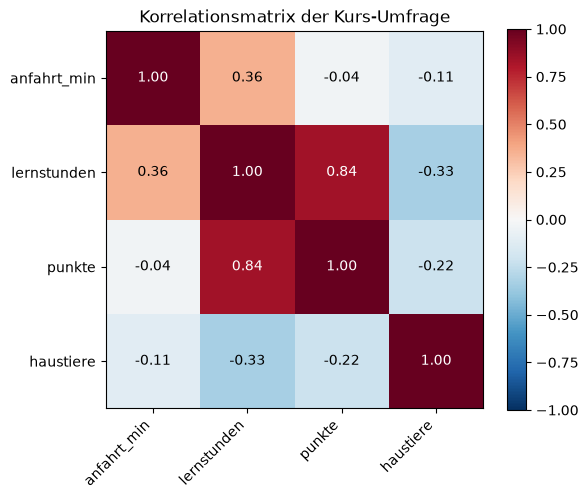

In [36]:
fig, ax = plt.subplots(figsize=(6, 5))
bild = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)

# Beschriftung der Achsen
ax.set_xticks(range(len(matrix)), matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(matrix)), matrix.columns)

# Zahlen in die Felder schreiben
for i in range(len(matrix)):
    for j in range(len(matrix)):
        wert = matrix.iloc[i, j]
        farbe = "white" if abs(wert) > 0.6 else "black"   # helle Schrift auf dunklen Feldern
        ax.text(j, i, f"{wert:.2f}", ha="center", va="center", color=farbe)

fig.colorbar(bild)
ax.set_title("Korrelationsmatrix der Kurs-Umfrage")
fig.tight_layout()
plt.show()

`vmin=-1, vmax=1` legt die Farbskala fest, sonst wäre der kleinste Wert der Matrix dunkelblau, auch wenn er nahe 0 liegt.

> **Gut zu wissen:** Die Bibliothek `seaborn` zeichnet dieselbe Heatmap mit einem einzigen Befehl (`sns.heatmap`). Wir bleiben bei Matplotlib.

## 17 – Das stärkste Paar finden

Bei vier Spalten liest man das stärkste Paar noch ab. Bei vielen Spalten hilft Pandas.

1. `stack()` macht aus der Matrix eine lange Liste von Paaren.
2. Ein Filter entfernt die Diagonale und die doppelten Paare.
3. Danach sortieren, wie bei Top-N.

In [37]:
paare = matrix.stack().reset_index()
paare.columns = ["merkmal_1", "merkmal_2", "r"]
print(paare.head(16))

      merkmal_1    merkmal_2         r
0   anfahrt_min  anfahrt_min  1.000000
1   anfahrt_min  lernstunden  0.359178
2   anfahrt_min       punkte -0.038726
3   anfahrt_min    haustiere -0.109577
4   lernstunden  anfahrt_min  0.359178
5   lernstunden  lernstunden  1.000000
6   lernstunden       punkte  0.841317
7   lernstunden    haustiere -0.332240
8        punkte  anfahrt_min -0.038726
9        punkte  lernstunden  0.841317
10       punkte       punkte  1.000000
11       punkte    haustiere -0.216497
12    haustiere  anfahrt_min -0.109577
13    haustiere  lernstunden -0.332240
14    haustiere       punkte -0.216497
15    haustiere    haustiere  1.000000


In [38]:
# "<" vergleicht Texte alphabetisch: Die Diagonale fällt weg, jedes Paar bleibt einmal übrig
paare = paare[paare["merkmal_1"] < paare["merkmal_2"]]

# Stärke ist der Betrag von r
paare["staerke"] = paare["r"].abs()
paare.sort_values("staerke", ascending=False).round(2)

,merkmal_1,merkmal_2,r,staerke
6,lernstunden,punkte,0.84,0.84
1,anfahrt_min,lernstunden,0.36,0.36
13,haustiere,lernstunden,-0.33,0.33
14,haustiere,punkte,-0.22,0.22
3,anfahrt_min,haustiere,-0.11,0.11
2,anfahrt_min,punkte,-0.04,0.04


<img src="png%20Dateien/nils_eichhoernchen.png" alt="Nils" width="110">

**Nils:** „Sechs Zahlen, und ich sehe alle Zusammenhänge auf einen Blick."

Der stärkste Zusammenhang ist Lernstunden und Punkte (0,84), der schwächste Anfahrt und Punkte (−0,04).

### Übung 5

- **a)** Erstelle die Spearman-Matrix für `anfahrt_min`, `lernstunden`, `punkte`, `haustiere` und `tshirt_nr`.
- **b)** Finde mit der Methode aus Abschnitt 17 das stärkste und das schwächste Paar.
- **c)** Zeichne die Matrix als Heatmap.

In [39]:
# a)
num5 = umfrage[["anfahrt_min", "lernstunden", "punkte", "haustiere", "tshirt_nr"]]
matrix_sp = num5.corr(method="spearman")
matrix_sp.round(2)


,anfahrt_min,lernstunden,punkte,haustiere,tshirt_nr
anfahrt_min,1.00,0.21,0.03,-0.01,0.25
lernstunden,0.21,1.00,0.88,-0.32,0.19
punkte,0.03,0.88,1.00,-0.26,0.21
haustiere,-0.01,-0.32,-0.26,1.00,-0.02
tshirt_nr,0.25,0.19,0.21,-0.02,1.00


In [40]:
# b)
paare_sp = matrix_sp.stack().reset_index()
paare_sp.columns = ["merkmal_1", "merkmal_2", "rho"]
paare_sp = paare_sp[paare_sp["merkmal_1"] < paare_sp["merkmal_2"]]
paare_sp["staerke"] = paare_sp["rho"].abs()
paare_sp = paare_sp.sort_values("staerke", ascending=False)

print(paare_sp.head(1).round(2))
print()
print(paare_sp.tail(1).round(2))

# Antwort: Lernstunden und Punkte (0,88) am stärksten,
#          Anfahrt und Haustiere (-0,01) am schwächsten.


     merkmal_1 merkmal_2   rho  staerke
7  lernstunden    punkte  0.88     0.88

     merkmal_1  merkmal_2   rho  staerke
3  anfahrt_min  haustiere -0.01     0.01


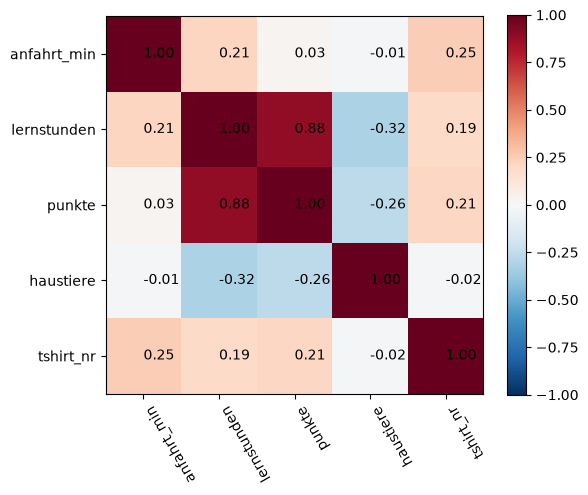

In [68]:
# c)
fig, ax = plt.subplots(figsize=(6,5))
bild = ax.imshow(matrix_sp, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(matrix_sp)), matrix_sp.columns, rotation=120, ha="left")
ax.set_yticks(range(len(matrix_sp)), matrix_sp.columns)
for i in range(len(matrix_sp)):
    for j in range(len(matrix_sp)):
        wert = matrix_sp.iloc[i, j]
        # farbe = "white" if abs(wert) > 0.6 else "black"
        ax.text(j, i, f"{wert:.2f}", ha="left", va="center")
fig.colorbar(bild)
fig.tight_layout()
plt.show()

---
# Block F – Weitere Übungen

Jede Übung nennt den Block, zu dem sie gehört.

- **Übung 6 bis 9:** Gegenprobe zu deinen Handrechnungen vom Vormittag.
- **Übung 10:** Die Charts.
- **Übung 11 und 12:** Die TechAcademy GmbH.

## 18 – Gegenprobe zum Vormittag

Lege deine Lösungen vom Vormittag daneben und vergleiche. Pandas schreibt Dezimalzahlen mit Punkt.

### Übung 6 – Pearson von Hand nachrechnen (zu Block A)

Übung 1 vom Vormittag: Übungsstunden (x) und Tippfehler (y).

- **a)** Lege einen DataFrame mit `stunden = [1, 2, 3, 4, 5]` und `fehler = [10, 12, 8, 6, 4]` an.
- **b)** Baue die Handtabelle nach (Abweichungen, Produkt, Quadrate) und berechne r.
- **c)** Prüfe mit `corr()`.

In [42]:
# a)


In [43]:
# b)


In [44]:
# c)


### Übung 7 – Spearman von Hand nachrechnen (zu Block C)

Übungen 5, 6 und 7 vom Vormittag.

- **a)** Schlaf `[6, 8, 5, 7, 9]` und Testpunkte `[60, 75, 62, 70, 72]`: Bilde die Ränge beider Spalten, berechne ρ und zum Vergleich Pearson.
- **b)** Zwei Jurys: Personalabteilung `[1, 2, 3, 4, 5]`, Teamleitung `[3, 1, 2, 5, 4]`. Wie einig sind sie sich?
- **c)** Bilde die Ränge für die Anfahrtszeiten 12, 15, 15, 20, 31.

In [45]:
# a)


In [46]:
# b)


In [47]:
# c)


### Übung 8 – r schätzen (zu Block B)

Übung 2 vom Vormittag, diesmal mit Wolken aus dem Computer. Führe die Zelle aus. **Schätze** für jede Wolke r, bevor du weiterrechnest. Notiere deine Schätzung als Kommentar.

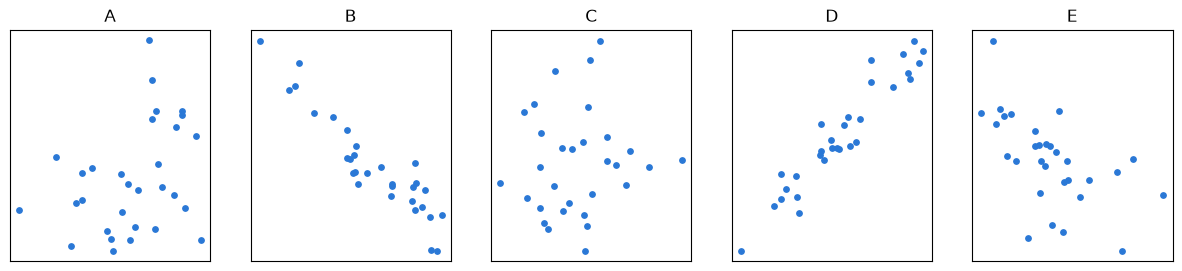

In [48]:
zufall = np.random.default_rng(42)
geheim = [0.45, -0.95, 0.0, 0.95, -0.6]
wolken = {}

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, buchstabe, ziel in zip(axes, "ABCDE", geheim):
    a = zufall.normal(size=30)
    b = ziel * a + (1 - ziel ** 2) ** 0.5 * zufall.normal(size=30)
    wolken[buchstabe] = pd.DataFrame({"x": a, "y": b})
    ax.scatter(a, b, color=BLAU, s=15)
    ax.set_title(buchstabe)
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

- **a)** Schreibe deine Schätzungen für A bis E auf.
- **b)** Berechne für jede Wolke r mit `corr()`. Die Wolken liegen im Dictionary `wolken`, zum Beispiel `wolken["A"]`.

In [49]:
# a)


In [50]:
# b)


### Übung 9 – Herrn Bauchgefühls Schlagzeilen (zu Block D)

<img src="png%20Dateien/mats_maulwurf_huegel.png" alt="Mats Maulwurf" width="120">

Übung 9 vom Vormittag, ohne Code. Nimm an, die Zusammenhänge wurden wirklich so gemessen. Welche Erklärung passt am besten: dritte Variable, umgekehrte Richtung oder gemeinsamer Trend? Wo steckt Mats?

1. „Kinder mit größeren Füßen lesen besser."
2. „Wer oft beim Arzt ist, ist öfter krank. Arztbesuche machen krank!"
3. „Je mehr Feuerwehrleute im Einsatz sind, desto größer ist der Schaden."
4. „Seit 2015 steigen die Zahl der Smartphones und die Zahl der Zahnarztpraxen. Smartphones schaden den Zähnen!"
5. „Wer ein Fitness-Armband trägt, ist sportlicher."

Schreibe deine Antworten als Kommentare in die Zelle.

In [51]:
# Übung 9


## 19 – Die Charts

### Übung 10 – Platzierungen und Wochen in den Charts (zu Block C und E)

Lies die UK-Charts von 1964 ein. Die Spalten: `Pos` (Platz diese Woche), `LW` (Platz letzte Woche), `Peak Pos` (beste Platzierung), `WoC` (Wochen in den Charts).

```python
ordner = "csv & excel Dateien/"
charts = pd.read_csv(ordner + "UK-top40-1964-1-2.tsv", sep="\t")
```

- **a)** Prüfe die Datentypen mit `charts.dtypes`. Warum ist `LW` keine Zahl? Lege eine Spalte `LW_zahl` mit `pd.to_numeric(charts["LW"], errors="coerce")` an. Wie viele Werte fehlen jetzt?
- **b)** Platzierungen sind ordinal. Erstelle die Spearman-Matrix für `Pos`, `LW_zahl`, `Peak Pos` und `WoC`.
- **c)** `Peak Pos` und `WoC` haben ein negatives ρ. Heißt das: Je besser ein Song, desto kürzer bleibt er in den Charts?

In [52]:
# a)


In [53]:
# b)


In [54]:
# c)


## 20 – Zweiter Schauplatz: die TechAcademy GmbH

Führe die folgende Zelle aus. Sie erstellt zwei DataFrames: `teilnehmende` (ein Python-Grundlagenkurs, eine Zeile pro Person) und `fitness` (Monatsdaten eines Fitnessstudios, mit dem die TechAcademy kooperiert).

In [55]:
# Teilnehmerdaten Python Grundlagen
teilnehmende = pd.DataFrame({
    "Lernstunden_pro_Woche":   [4, 6, 9, 2, 11, 13, 7, 15, 5, 10],
    "Uebungsaufgaben_geloest": [12, 18, 28, 6, 34, 40, 21, 46, 15, 31],
    "Fehlzeiten_Tage":         [5, 3, 1, 8, 1, 0, 2, 0, 6, 2],
    "Abschlussnote":           [3.3, 2.7, 1.7, 4.0, 1.3, 1.0, 2.3, 1.0, 3.7, 1.7],
})

# Monatsdaten eines Fitnessstudios (Januar bis Dezember)
fitness = pd.DataFrame({
    "Temperatur_C":       [22, 19, 15, 8, 4, 2, 5, 9, 14, 20, 24, 26],
    "Mitglieder_aktiv":   [180, 210, 260, 310, 330, 340, 325, 300, 265, 220, 190, 170],
    "Smoothie_Verkaeufe": [95, 80, 60, 35, 20, 15, 22, 40, 65, 85, 100, 110],
    "Kurs_Buchungen":     [120, 145, 175, 200, 215, 220, 210, 195, 172, 148, 130, 115],
})

teilnehmende.head()

,Lernstunden_pro_Woche,Uebungsaufgaben_geloest,Fehlzeiten_Tage,Abschlussnote
0,4,12,5,3.3
1,6,18,3,2.7
2,9,28,1,1.7
3,2,6,8,4.0
4,11,34,1,1.3


### Übung 11 – Lernen, Fehlen und die Note (zu Block A und E)

Arbeite mit `teilnehmende`. In Deutschland ist 1,0 die beste Note.

- **a)** Berechne r für Lernstunden und Abschlussnote sowie für Fehlzeiten und Abschlussnote. Was bedeuten die Vorzeichen hier?
- **b)** Zeichne beide Zusammenhänge als Streudiagramme nebeneinander. *Hinweis: `ax.invert_yaxis()` stellt die Note 1,0 nach oben.*
- **c)** Erstelle die Korrelationsmatrix. `Lernstunden_pro_Woche` und `Uebungsaufgaben_geloest` haben r = 1,00. Was heißt das für eine Auswertung?

In [56]:
# a)


In [57]:
# b)


In [58]:
# c)


### Übung 12 – Vertreiben Smoothies die Mitglieder? (zu Block D und E)

<img src="png%20Dateien/herr_bauchgefuehl.png" alt="Herr Bauchgefühl" width="120">

> **Herr Bauchgefühl:** „In Monaten mit vielen Smoothies sind kaum Mitglieder im Studio. Die Smoothies vertreiben die Leute. Weg damit!"

Arbeite mit `fitness`.

- **a)** Berechne r für `Smoothie_Verkaeufe` und `Mitglieder_aktiv`.
- **b)** Erstelle die Korrelationsmatrix und finde mit der Methode aus Abschnitt 17 die drei stärksten Paare.
- **c)** Zeichne die Matrix als Heatmap.
- **d)** Hat Herr Bauchgefühl recht? Wo steckt Mats?

In [59]:
# a)


In [60]:
# b)


In [61]:
# c)


In [62]:
# d)


---
## 21 – Zusammenfassung

| Aufgabe | Befehl |
|---|---|
| Kovarianz | `x.cov(y)` |
| Pearson r | `x.corr(y)` |
| Spearman ρ | `x.corr(y, method="spearman")` |
| Ränge | `x.rank()` (gleiche Werte: Durchschnittsrang) |
| Ordinale Texte als Zahlen | `pd.Categorical(..., categories=[...], ordered=True).codes` |
| Korrelationsmatrix | `df[[...]].corr()`, `df[[...]].corr(method="spearman")` |
| Nur Zahlenspalten | `df.corr(numeric_only=True)` (Vorsicht bei ID-Spalten) |
| Heatmap | `ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)` |
| Paare aus der Matrix | `matrix.stack().reset_index()`, Filter `merkmal_1 < merkmal_2` |
| Text in Zahl umwandeln | `pd.to_numeric(spalte, errors="coerce")` |

**Welches Maß wann?**

| Merkmale | Werkzeug |
|---|---|
| zwei metrische, Zusammenhang ungefähr gerade | Pearson r |
| mindestens ein ordinales, oder Kurve, oder Ausreißer | Spearman ρ |
| zwei nominale | Kreuztabelle (`pd.crosstab`) |
| ein nominales und ein metrisches | Gruppen-Boxplots |

**Vier Fragen an jede Korrelation:** dritte Variable? umgekehrte Richtung? nur Zeittrend oder kleine Stichprobe? Experiment mit Zufallsgruppen?

---
*Material erstellt von Julia Brutskaya*